In [ ]:
# Smart Inventory & Stock-Out Prediction System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Generate Retail Inventory Dataset

np.random.seed(42)

n = 5000

products = [f"P{str(i).zfill(3)}" for i in range(1, 51)]
categories = ["Electronics", "Grocery", "Clothing", "Beauty", "Home"]

data = pd.DataFrame({
    "Date": pd.date_range(start="2025-01-01", periods=n, freq="h"),
    "Product_ID": np.random.choice(products, n),
    "Category": np.random.choice(categories, n),
    "Units_Sold": np.random.randint(1, 30, n),
    "Current_Stock": np.random.randint(5, 200, n),
    "Price": np.round(np.random.uniform(100, 5000, n), 2),
    "Discount": np.random.randint(0, 31, n),
    "Lead_Time": np.random.randint(1, 15, n)
})

data.head()

,Date,Product_ID,Category,Units_Sold,Current_Stock,Price,Discount,Lead_Time
0,2025-01-01 00:00:00,P039,Home,22,23,3055.63,15,4
1,2025-01-01 01:00:00,P029,Electronics,23,28,813.84,21,14
2,2025-01-01 02:00:00,P015,Home,14,88,3659.71,3,14
3,2025-01-01 03:00:00,P043,Grocery,26,171,1116.55,29,14
4,2025-01-01 04:00:00,P008,Home,25,96,2221.72,27,4


In [ ]:
# Basic Dataset Information

print("Dataset Shape:", data.shape)

print("\nColumn Information:")
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

Dataset Shape: (5000, 8)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           5000 non-null   datetime64[ns]
 1   Product_ID     5000 non-null   object        
 2   Category       5000 non-null   object        
 3   Units_Sold     5000 non-null   int64         
 4   Current_Stock  5000 non-null   int64         
 5   Price          5000 non-null   float64       
 6   Discount       5000 non-null   int64         
 7   Lead_Time      5000 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(4), object(2)
memory usage: 312.6+ KB
None

Missing Values:
Date             0
Product_ID       0
Category         0
Units_Sold       0
Current_Stock    0
Price            0
Discount         0
Lead_Time        0
dtype: int64

Duplicate Rows:
0


In [ ]:
# Statistical Summary

data.describe()

,Date,Units_Sold,Current_Stock,Price,Discount,Lead_Time
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2025-04-15 03:29:59.999999744,15.210000,101.424600,2536.318048,14.985400,7.533600
min,2025-01-01 00:00:00,1.000000,5.000000,100.860000,0.000000,1.000000
25%,2025-02-22 01:45:00,8.000000,52.000000,1313.855000,7.000000,4.000000
50%,2025-04-15 03:30:00,15.000000,101.000000,2522.770000,15.000000,8.000000
75%,2025-06-06 05:15:00,22.000000,151.000000,3712.062500,23.000000,11.000000
max,2025-07-28 07:00:00,29.000000,199.000000,4999.470000,30.000000,14.000000
std,NaN,8.360734,57.007227,1404.552081,8.919703,4.034467


In [ ]:
# Category-wise Sales Analysis

category_sales = data.groupby("Category")["Units_Sold"].sum().sort_values(ascending=False)

print(category_sales)

Category
Grocery        16496
Clothing       15202
Beauty         14987
Electronics    14821
Home           14544
Name: Units_Sold, dtype: int64


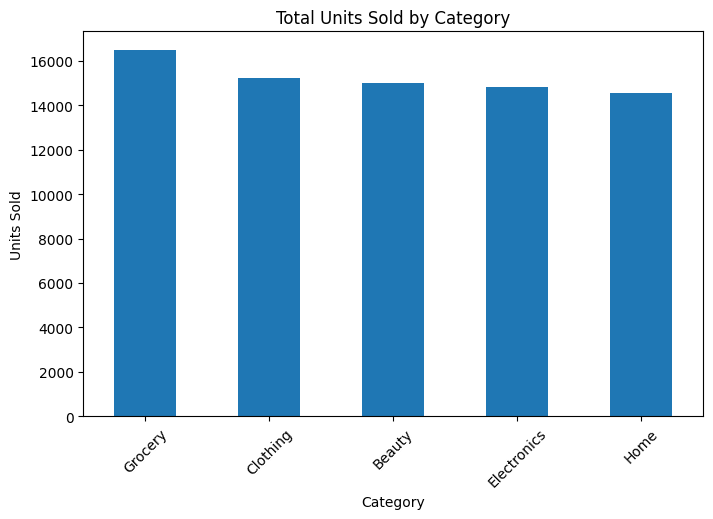

In [ ]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Calculate Expected Demand During Lead Time

data["Expected_Demand"] = data["Units_Sold"] * data["Lead_Time"]

# Calculate Stock Coverage Ratio
data["Stock_Coverage_Ratio"] = (
    data["Current_Stock"] / (data["Units_Sold"] + 1)
)

# Create Stock-Out Risk
data["Stockout_Risk"] = np.where(
    data["Current_Stock"] < data["Expected_Demand"],
    1,
    0
)

data.head()

,Date,Product_ID,Category,Units_Sold,Current_Stock,Price,Discount,Lead_Time,Expected_Demand,Stock_Coverage_Ratio,Stockout_Risk
0,2025-01-01 00:00:00,P039,Home,22,23,3055.63,15,4,88,1.000000,1
1,2025-01-01 01:00:00,P029,Electronics,23,28,813.84,21,14,322,1.166667,1
2,2025-01-01 02:00:00,P015,Home,14,88,3659.71,3,14,196,5.866667,1
3,2025-01-01 03:00:00,P043,Grocery,26,171,1116.55,29,14,364,6.333333,1
4,2025-01-01 04:00:00,P008,Home,25,96,2221.72,27,4,100,3.692308,1


In [ ]:
# Check Stock-Out Risk Distribution

print(data["Stockout_Risk"].value_counts())

print("\nPercentage:")
print(data["Stockout_Risk"].value_counts(normalize=True) * 100)

Stockout_Risk
0    2520
1    2480
Name: count, dtype: int64

Percentage:
Stockout_Risk
0    50.4
1    49.6
Name: proportion, dtype: float64


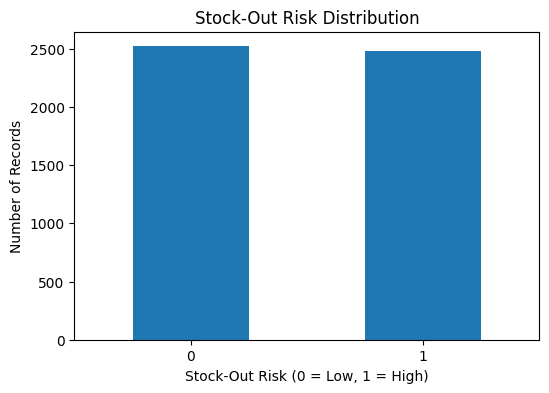

In [ ]:
plt.figure(figsize=(6, 4))

data["Stockout_Risk"].value_counts().plot(kind="bar")

plt.title("Stock-Out Risk Distribution")
plt.xlabel("Stock-Out Risk (0 = Low, 1 = High)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Select Features for Machine Learning

features = [
    "Units_Sold",
    "Current_Stock",
    "Price",
    "Discount",
    "Lead_Time",
    "Expected_Demand",
    "Stock_Coverage_Ratio"
]

X = data[features]
y = data["Stockout_Risk"]

print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Units_Sold', 'Current_Stock', 'Price', 'Discount', 'Lead_Time', 'Expected_Demand', 'Stock_Coverage_Ratio']
X shape: (5000, 7)
y shape: (5000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 7)
Testing data: (1000, 7)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:20])

Predictions generated successfully!
[1 0 0 1 1 1 1 1 0 0 0 0 0 1 0 0 0 1 0 1]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 98.3 %

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       504
           1       0.98      0.98      0.98       496

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000



In [ ]:
# Feature Importance

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                Feature  Importance
6  Stock_Coverage_Ratio    0.314294
5       Expected_Demand    0.287824
1         Current_Stock    0.148970
4             Lead_Time    0.143967
0            Units_Sold    0.080779
2                 Price    0.014124
3              Discount    0.010042


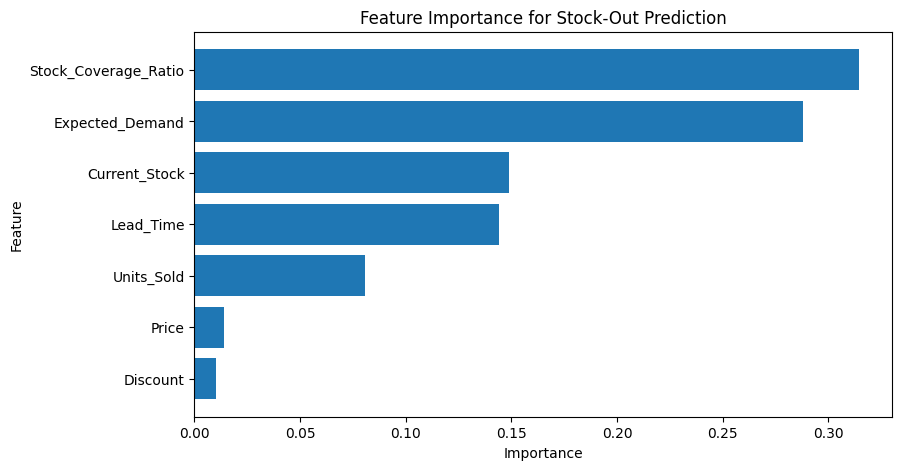

In [ ]:
plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for Stock-Out Prediction")
plt.gca().invert_yaxis()

plt.show()

In [ ]:
# Calculate Average Daily Demand

data["Average_Daily_Demand"] = data["Units_Sold"]

In [ ]:
# Calculate Safety Stock

data["Safety_Stock"] = (
    data["Average_Daily_Demand"] *
    data["Lead_Time"] *
    0.20
)

# Calculate Reorder Point

data["Reorder_Point"] = (
    data["Average_Daily_Demand"] *
    data["Lead_Time"] +
    data["Safety_Stock"]
)

data[[
    "Product_ID",
    "Current_Stock",
    "Average_Daily_Demand",
    "Lead_Time",
    "Safety_Stock",
    "Reorder_Point"
]].head(10)

,Product_ID,Current_Stock,Average_Daily_Demand,Lead_Time,Safety_Stock,Reorder_Point
0,P039,23,22,4,17.6,105.6
1,P029,28,23,14,64.4,386.4
2,P015,88,14,14,39.2,235.2
3,P043,171,26,14,72.8,436.8
4,P008,96,25,4,20.0,120.0
5,P021,186,15,8,24.0,144.0
6,P039,171,2,6,2.4,14.4
7,P019,149,24,2,9.6,57.6
8,P023,151,14,5,14.0,84.0
9,P011,122,16,4,12.8,76.8


In [ ]:
# Recommended Reorder Quantity

data["Recommended_Reorder_Qty"] = np.maximum(
    data["Reorder_Point"] - data["Current_Stock"],
    0
)

data[[
    "Product_ID",
    "Current_Stock",
    "Reorder_Point",
    "Recommended_Reorder_Qty"
]].head(10)

,Product_ID,Current_Stock,Reorder_Point,Recommended_Reorder_Qty
0,P039,23,105.6,82.6
1,P029,28,386.4,358.4
2,P015,88,235.2,147.2
3,P043,171,436.8,265.8
4,P008,96,120.0,24.0
5,P021,186,144.0,0.0
6,P039,171,14.4,0.0
7,P019,149,57.6,0.0
8,P023,151,84.0,0.0
9,P011,122,76.8,0.0


In [ ]:
# Inventory Action

data["Inventory_Action"] = np.where(
    data["Recommended_Reorder_Qty"] > 0,
    "REORDER",
    "NO REORDER"
)

data[[
    "Product_ID",
    "Current_Stock",
    "Stockout_Risk",
    "Recommended_Reorder_Qty",
    "Inventory_Action"
]].head(15)

,Product_ID,Current_Stock,Stockout_Risk,Recommended_Reorder_Qty,Inventory_Action
0,P039,23,1,82.6,REORDER
1,P029,28,1,358.4,REORDER
2,P015,88,1,147.2,REORDER
3,P043,171,1,265.8,REORDER
4,P008,96,1,24.0,REORDER
5,P021,186,0,0.0,NO REORDER
6,P039,171,0,0.0,NO REORDER
7,P019,149,0,0.0,NO REORDER
8,P023,151,0,0.0,NO REORDER
9,P011,122,0,0.0,NO REORDER


In [ ]:
import sqlite3

conn = sqlite3.connect("inventory.db")

data.to_sql(
    "inventory",
    conn,
    if_exists="replace",
    index=False
)

print("Inventory data loaded into SQL successfully!")

Inventory data loaded into SQL successfully!


In [ ]:
query = """
SELECT
    Product_ID,
    Category,
    Current_Stock,
    Stockout_Risk,
    Recommended_Reorder_Qty
FROM inventory
WHERE Inventory_Action = 'REORDER'
ORDER BY Recommended_Reorder_Qty DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

result

,Product_ID,Category,Current_Stock,Stockout_Risk,Recommended_Reorder_Qty
0,P036,Grocery,10,1,477.2
1,P023,Beauty,18,1,469.2
2,P007,Electronics,40,1,447.2
3,P006,Grocery,31,1,439.4
4,P031,Grocery,14,1,438.4
5,P029,Grocery,51,1,436.2
6,P037,Home,35,1,435.4
7,P045,Electronics,23,1,429.4
8,P028,Electronics,11,1,425.8
9,P044,Home,17,1,419.8


In [ ]:
query = """
SELECT
    Category,
    SUM(Units_Sold) AS Total_Units_Sold
FROM inventory
GROUP BY Category
ORDER BY Total_Units_Sold DESC;
"""

pd.read_sql_query(query, conn)

,Category,Total_Units_Sold
0,Grocery,16496
1,Clothing,15202
2,Beauty,14987
3,Electronics,14821
4,Home,14544


In [ ]:
query = """
SELECT
    Product_ID,
    Category,
    Current_Stock,
    Units_Sold,
    Lead_Time,
    Stockout_Risk
FROM inventory
WHERE Stockout_Risk = 1
ORDER BY Units_Sold DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,Product_ID,Category,Current_Stock,Units_Sold,Lead_Time,Stockout_Risk
0,P033,Clothing,33,29,4,1
1,P035,Home,125,29,10,1
2,P008,Clothing,38,29,6,1
3,P027,Beauty,58,29,10,1
4,P037,Grocery,157,29,14,1
5,P029,Home,186,29,11,1
6,P038,Clothing,75,29,11,1
7,P011,Clothing,29,29,10,1
8,P048,Clothing,148,29,13,1
9,P007,Electronics,153,29,7,1


In [ ]:
# Export Final Dataset for Power BI

data.to_csv(
    "Smart_Inventory_Final.csv",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!


In [ ]:
print(data.columns.tolist())

['Date', 'Product_ID', 'Category', 'Units_Sold', 'Current_Stock', 'Price', 'Discount', 'Lead_Time', 'Expected_Demand', 'Stock_Coverage_Ratio', 'Stockout_Risk', 'Average_Daily_Demand', 'Safety_Stock', 'Reorder_Point', 'Recommended_Reorder_Qty', 'Inventory_Action']


In [ ]:
readme = """
# Smart Inventory & Stock-Out Prediction System

## Project Overview
An end-to-end data analytics and machine learning project that analyzes retail inventory data, predicts stock-out risk, and recommends inventory reorder quantities.

## Objectives
- Analyze retail sales and inventory data
- Identify products at risk of stock-out
- Predict stock-out risk using machine learning
- Identify important factors affecting stock-out risk
- Calculate recommended reorder quantities
- Perform business analysis using SQL

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SQL
- Power BI

## Machine Learning
Random Forest Classifier was used to predict stock-out risk.

## Key Features
- Exploratory Data Analysis
- Stock-out Risk Prediction
- Feature Importance Analysis
- Reorder Point Calculation
- Recommended Reorder Quantity
- SQL Business Analysis

## Dataset
The project uses a simulated retail inventory dataset created for educational and portfolio purposes.

## Business Value
The system helps businesses identify inventory risks and make data-driven decisions about when products should be reordered.

## Project Status
Python analysis, machine learning, reorder recommendation and SQL analysis completed.
Power BI dashboard can be added as the visualization layer.
"""

with open("README.md", "w") as f:
    f.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [ ]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(readme)


# Smart Inventory & Stock-Out Prediction System

## Project Overview
An end-to-end data analytics and machine learning project that analyzes retail inventory data, predicts stock-out risk, and recommends inventory reorder quantities.

## Objectives
- Analyze retail sales and inventory data
- Identify products at risk of stock-out
- Predict stock-out risk using machine learning
- Identify important factors affecting stock-out risk
- Calculate recommended reorder quantities
- Perform business analysis using SQL

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SQL
- Power BI

## Machine Learning
Random Forest Classifier was used to predict stock-out risk.

## Key Features
- Exploratory Data Analysis
- Stock-out Risk Prediction
- Feature Importance Analysis
- Reorder Point Calculation
- Recommended Reorder Quantity
- SQL Business Analysis

## Dataset
The project uses a simulated retail inventory dataset created for educational and portfolio purposes.